# Problema 2 — 01: verificación de kernels circulares

Verificación numérica de los dos candidatos del examen y de los kernels
válidos de la tabla, siguiendo dos criterios:

1. **Coeficientes de Fourier:** un kernel radial sobre el círculo
   `k(t, t') = g(d(t, t'))` es positivo semidefinido si y solo si sus
   coeficientes de coseno `a_n = (2/pi) int_0^pi g(t) cos(n t) dt` son
   todos `>= 0` (criterio de Bochner en el círculo).
2. **Valores propios finitos:** con un conjunto finito de puntos
   (las 24 horas, los 7 días y las horas de la muestra de entrenamiento)
   la matriz de kernel debe ser positivo semidefinida. Se usa tolerancia
   relativa `1e-10 * lambda_max` porque hay puntos repetidos y errores de
   punto flotante del orden de `1e-16`.

Valores esperados del enunciado: `kI` tiene `a_4 ≈ -3.19e-4`,
`lambda_min(24h) ≈ -0.00505` y `lambda_min(7 días) ≈ +0.0326`;
`kII` tiene `a_3 ≈ -0.0712`, `lambda_min(24h) ≈ -0.839` y
`lambda_min(7 días) ≈ -0.197`.

In [1]:
"""Configuración, rutas e importaciones de la libreta."""

from __future__ import annotations

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.integrate import quad
from scipy.linalg import eigvalsh


def _buscar_raiz(inicio: Path) -> Path:
    """Sube desde el directorio actual hasta encontrar la raíz del repo."""
    for base in [inicio, *inicio.parents]:
        if (base / "common.py").exists() and (base / "problema-2").is_dir():
            return base
    return inicio


_AQUI = Path.cwd()
_RAIZ = _buscar_raiz(_AQUI)
_DIR_PROBLEMA = _RAIZ / "problema-2" if (_RAIZ / "problema-2").is_dir() else _RAIZ
for _ruta in (_RAIZ, _DIR_PROBLEMA):
    if str(_ruta) not in sys.path:
        sys.path.insert(0, str(_ruta))

from common import SEED  # noqa: E402
import data as da  # noqa: E402
import kernels as kk  # noqa: E402

RESULTADOS = _RAIZ / "resultados"
RESULTADOS.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_rows", None)
pd.set_option("display.width", 220)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

# Kernels a verificar. Los puntos de quiebre de la integral se dan para
# mejorar la cuadratura en los vértices (kII: t = 2; tri: t = 2).
KERNELS = {
    "kI": (kk.k_I, ()),
    "kII": (kk.k_II, (2.0,)),
    "vonMises (kappa=1)": (lambda d: kk.k_von_mises(d, 1.0), ()),
    "exp(-d/1)": (lambda d: kk.k_exp_minus(d, 1.0), ()),
    "max(0, 1-d/2)": (kk.k_tri, (2.0,)),
    "pi^2/6-pi*d/2+d^2/4": (kk.k_poly_circular, ()),
}
N_COEF = 40
TOL_NEG = -1e-9          # umbral para llamar a un coeficiente "negativo"
TOL_REL = 1e-10          # tolerancia relativa de valores propios

print(f"SEED = {SEED}")
print(f"Kernels a verificar: {list(KERNELS)}")

SEED = 223210350
Kernels a verificar: ['kI', 'kII', 'vonMises (kappa=1)', 'exp(-d/1)', 'max(0, 1-d/2)', 'pi^2/6-pi*d/2+d^2/4']


## 1. La distancia circular y su arco más corto

Con periodo `P`, `d(x, y) = 2*pi*min(delta, P-delta)/P` con
`delta = |x - y|` módulo `P`. En el código `circ_dist` hace broadcasting,
así que un vector de horas contra un vector de horas devuelve la matriz
completa de distancias. Los dos ejemplos del inciso (a) de la teoría deben
dar `pi/6` (23:00 contra 01:00) y `4*pi/7` (sábado contra lunes).

In [2]:
muestra, prueba = da.dividir_muestra_prueba(da.cargar_dataframe(), seed=SEED)
print(f"Muestra de entrenamiento: {len(muestra)} horas, "
      f"{muestra['dteday'].min().date()} a {muestra['dteday'].max().date()}.")
print(f"Prueba (no se toca): {len(prueba)} horas, "
      f"{prueba['dteday'].min().date()} a {prueba['dteday'].max().date()}.")

d1 = float(kk.circ_dist(np.array([23.0]), np.array([1.0]), 24).ravel()[0])
d2 = float(kk.circ_dist(np.array([6.0]), np.array([1.0]), 7).ravel()[0])
print(f"d(23h, 1h) = {d1:.10f}  (esperado pi/6 = {np.pi/6:.10f})")
print(f"d(sab=6, lun=1) = {d2:.10f}  (esperado 4*pi/7 = {4*np.pi/7:.10f})")
assert abs(d1 - np.pi / 6) < 1e-12
assert abs(d2 - 4 * np.pi / 7) < 1e-12

# Broadcasting: 3 horas contra 5 días devuelve una matriz 3x5 cuando se usan
# las formas columna (3, 1) y fila (1, 5), como hace kernel_matrix.
prueba_bc = kk.circ_dist(
    np.array([23.0, 0.0, 5.0])[:, None],
    np.array([1.0, 2.0, 3.0, 4.0, 0.0])[None, :],
    24,
)
print(f"Broadcasting: {prueba_bc.shape} (esperado (3, 5)).")
print("Auto-distancia (debe ser 0): "
      f"{float(kk.circ_dist(np.array([3.0]), np.array([3.0]), 24).ravel()[0]):.1f}")

Muestra de entrenamiento: 3000 horas, 2011-01-01 a 2012-09-30.
Prueba (no se toca): 2168 horas, 2012-10-01 a 2012-12-31.
d(23h, 1h) = 0.5235987756  (esperado pi/6 = 0.5235987756)
d(sab=6, lun=1) = 1.7951958021  (esperado 4*pi/7 = 1.7951958021)
Broadcasting: (3, 5) (esperado (3, 5)).
Auto-distancia (debe ser 0): 0.0


La distancia reproduce los dos ejemplos del enunciado y el broadcasting
devuelve matrices rectangulares, que es justo lo que necesita
`kernel_matrix` para conjuntos de distinto tamaño (entrenamiento contra
validación, entrenamiento contra prueba).

## 2. Coeficientes de Fourier: cuáles son negativos

Para cada kernel se integran los primeros 40 coeficientes
`a_n = (2/pi) int_0^pi g(t) cos(n t) dt` con cuadratura adaptativa de
`scipy`. En las gráficas, los coeficientes negativos se marcan en rojo y
los no negativos en azul. Por la teoría, un kernel válido no puede tener
ningún coeficiente (claramente) negativo: si aparece uno, el kernel no es
positivo semidefinido y por tanto no es un kernel.

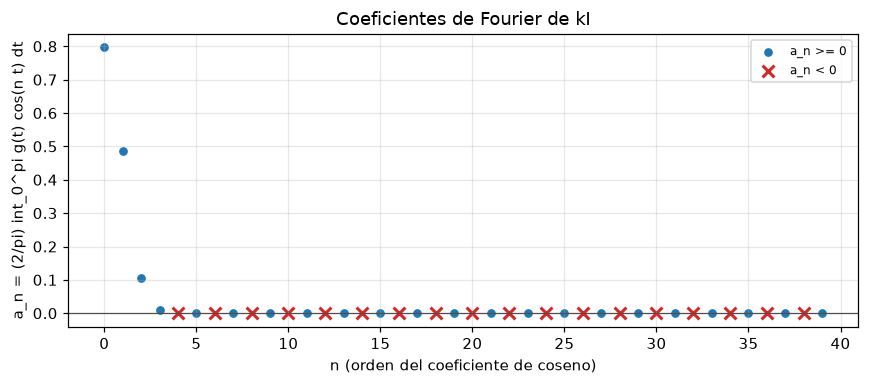

kI: min a_n = -3.288e-04, max a_n = 7.965e-01, negativos = 18


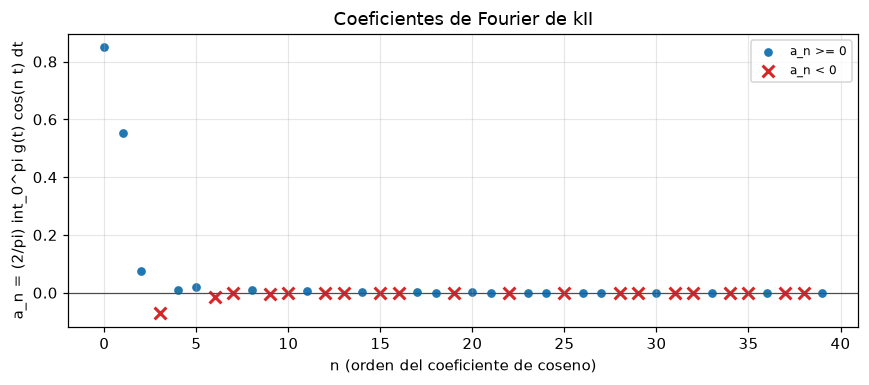

kII: min a_n = -7.121e-02, max a_n = 8.488e-01, negativos = 20


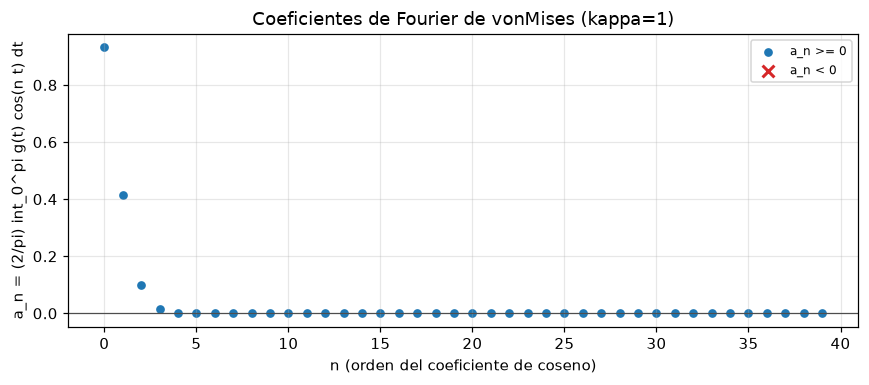

vonMises (kappa=1): min a_n = -2.054e-16, max a_n = 9.315e-01, negativos = 0


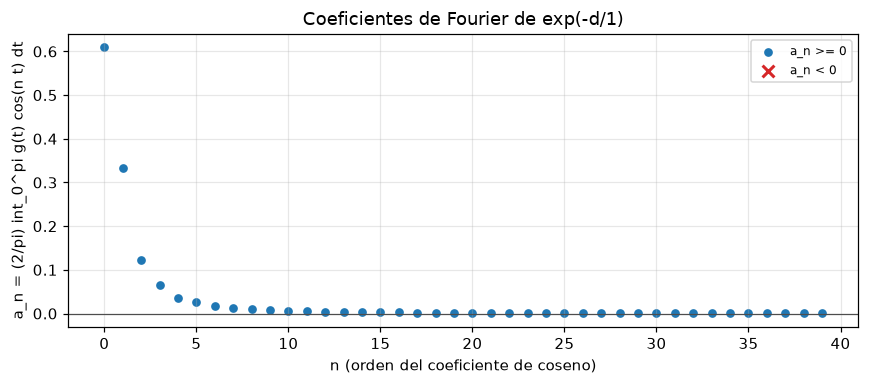

exp(-d/1): min a_n = 4.215e-04, max a_n = 6.091e-01, negativos = 0


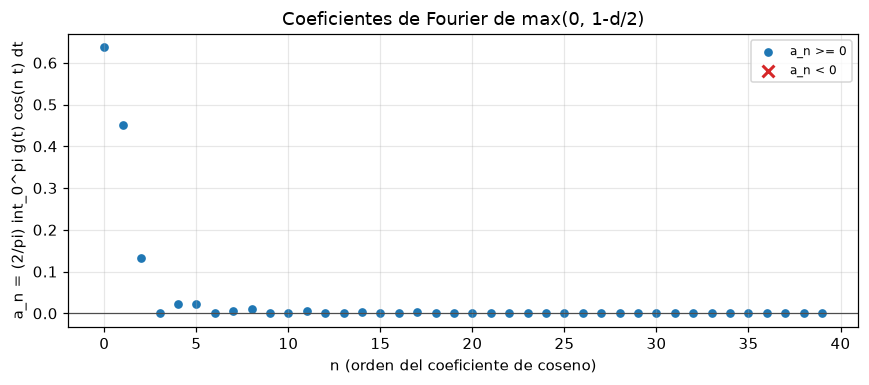

max(0, 1-d/2): min a_n = 1.031e-07, max a_n = 6.366e-01, negativos = 0


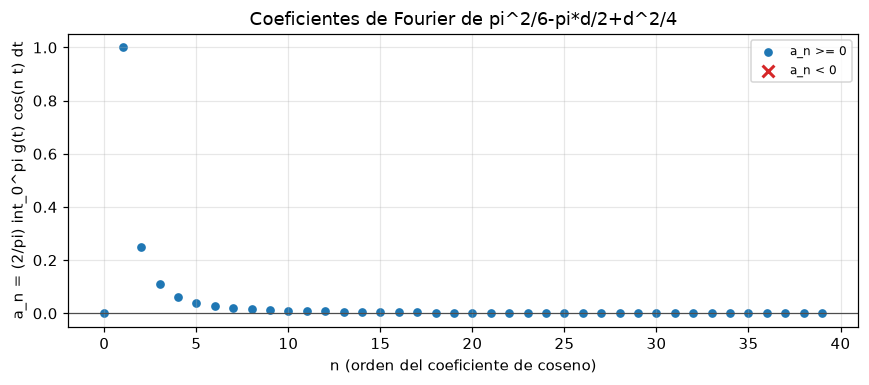

pi^2/6-pi*d/2+d^2/4: min a_n = 1.665e-16, max a_n = 1.000e+00, negativos = 0


,kernel,a_n_min,a_n_max,n_negativos,n_negativos_lista
0,kI,-3.287934e-04,0.796544,18,"[4, 6, 8, 10, 12, 14, 16, 18, 20, 22]"
1,kII,-7.121225e-02,0.848826,20,"[3, 6, 7, 9, 10, 12, 13, 15, 16, 19]"
2,vonMises (kappa=1),-2.054108e-16,0.931519,0,[]
3,exp(-d/1),4.215287e-04,0.609109,0,[]
4,"max(0, 1-d/2)",1.030504e-07,0.636620,0,[]
5,pi^2/6-pi*d/2+d^2/4,1.665335e-16,1.000000,0,[]


In [3]:
def coeficientes_fourier(g, puntos_quiebre: tuple, n_max: int = N_COEF) -> np.ndarray:
    """Integra los coeficientes de coseno de un kernel radial g."""
    valores = []
    for n in range(n_max):
        valor, _error = quad(
            lambda t: g(t) * np.cos(n * t),
            0.0, float(np.pi),
            points=list(puntos_quiebre),
            epsabs=1e-13, epsrel=1e-12, limit=300,
        )
        valores.append(2.0 / np.pi * valor)
    return np.asarray(valores)


filas_coef = []
resumen_coef = []
for nombre, (g, quiebres) in KERNELS.items():
    coef = coeficientes_fourier(g, quiebres)
    neg = coef < TOL_NEG
    fig, ax = plt.subplots(figsize=(8, 3.6))
    ax.scatter(np.arange(N_COEF)[~neg], coef[~neg], s=22, color="tab:blue",
               label="a_n >= 0")
    ax.scatter(np.arange(N_COEF)[neg], coef[neg], s=60, color="tab:red",
               marker="x", linewidths=2, label="a_n < 0")
    ax.axhline(0.0, color="0.3", linewidth=0.8)
    ax.set_xlabel("n (orden del coeficiente de coseno)")
    ax.set_ylabel("a_n = (2/pi) int_0^pi g(t) cos(n t) dt")
    ax.set_title(f"Coeficientes de Fourier de {nombre}")
    ax.legend(loc="upper right", fontsize=8)
    fig.tight_layout()
    ruta_fig = RESULTADOS / f"p2_01_fourier_{nombre.replace(' ','_').replace('(','').replace(')','').replace('/','_')}.png"
    fig.savefig(ruta_fig, bbox_inches="tight")
    plt.show()
    for n, v in enumerate(coef):
        filas_coef.append({"kernel": nombre, "n": n, "a_n": float(v),
                           "negativo": "sí" if v < TOL_NEG else "no"})
    resumen_coef.append({
        "kernel": nombre,
        "a_n_min": float(coef.min()),
        "a_n_max": float(coef.max()),
        "n_negativos": int(neg.sum()),
        "n_negativos_lista": str([int(i) for i in np.flatnonzero(neg)][:10]),
    })
    print(f"{nombre}: min a_n = {coef.min():.3e}, "
          f"max a_n = {coef.max():.3e}, negativos = {int(neg.sum())}")

tabla_coef = pd.DataFrame(filas_coef)
tabla_coef.to_csv(RESULTADOS / "p2_01_coeficientes.csv", index=False, float_format="%.10f")
tabla_resumen_coef = pd.DataFrame(resumen_coef)
display(tabla_resumen_coef)
tabla_resumen_coef.to_csv(RESULTADOS / "p2_01_resumen_coeficientes.csv", index=False, float_format="%.10f")

El resultado es el esperado y es consistente con la teoría:

- **`kI`** tiene coeficientes negativos desde `n = 4` (`a_4 ≈ -3.19e-4`,
  con más detrás y alternando con positivos). Por tanto **no es** un kernel
  positivo semidefinido: los coeficientes negativos delatan el problema.
- **`kII`** tiene `a_3 ≈ -0.0712` (y muchos más negativos). Tampoco es un
  kernel.
- **Los cuatro kernels de la tabla no tienen ningún coeficiente negativo**
  (el mínimo es ~1e-16 en von Mises y positivo en los otros), consistente
  con que son kernels válidos. La tolerancia de cuadratura introduce ruido
  del orden de 1e-16, muy por debajo del umbral de −1e-9.

## 3. Valores propios mínimos de las matrices finitas

Aunque un kernel tenga coeficientes negativos, aún podría parecer
positivo semidefinido en un conjunto finito pequeño si la resolución es
insuficiente. Por eso el inciso pide comprobar tres conjuntos: las 24
horas, los 7 días y las 3000 horas de la muestra de entrenamiento (con
puntos repetidos, así que la matriz es degenerada). Se usa
`scipy.linalg.eigvalsh(..., subset_by_index=[0, 0])` para obtener solo el
menor valor propio, y se compara con la tolerancia relativa
`1e-10 * lambda_max`.

In [4]:
def lambda_min_matriz(K: np.ndarray) -> tuple[float, float]:
    """Menor y mayor valor propio de una matriz simétrica."""
    lmin = float(eigvalsh(K, subset_by_index=[0, 0])[0])
    lmax = float(eigvalsh(K, subset_by_index=[K.shape[0] - 1, K.shape[0] - 1])[0])
    return lmin, lmax


horas24 = np.arange(24, dtype=float)
dias7 = np.arange(7, dtype=float)
horas_muestra = muestra["hr"].to_numpy(dtype=float)  # 3000 valores, con repeticiones
print(f"Horas de la muestra: {len(horas_muestra)} valores, "
      f"{len(np.unique(horas_muestra))} horas distintas.")

filas_eigen = []
for nombre, (g, _quiebres) in KERNELS.items():
    for conjunto, pts, periodo in (
        ("24 horas", horas24, 24),
        ("7 días", dias7, 7),
        ("horas muestra (3000)", horas_muestra, 24),
    ):
        K = kk.kernel_matrix(pts, pts, g, periodo)
        lmin, lmax = lambda_min_matriz(K)
        tol = TOL_REL * lmax
        filas_eigen.append({
            "kernel": nombre,
            "conjunto": conjunto,
            "lambda_min": lmin,
            "lambda_max": lmax,
            "tolerancia": tol,
            "negativo_claro": "sí" if lmin < -tol else "no",
        })

tabla_eigen = pd.DataFrame(filas_eigen)
display(tabla_eigen.round(6))
tabla_eigen.to_csv(RESULTADOS / "p2_01_eigenvalores.csv", index=False, float_format="%.10f")

Horas de la muestra: 3000 valores, 24 horas distintas.


,kernel,conjunto,lambda_min,lambda_max,tolerancia,negativo_claro
0,kI,24 horas,-0.005053,9.557548,0.0,sí
1,kI,7 días,0.032615,2.789335,0.0,no
2,kI,horas muestra (3000),-0.642452,1194.845964,0.0,sí
3,kII,24 horas,-0.839403,10.202276,0.0,sí
4,kII,7 días,-0.196680,2.985795,0.0,sí
5,kII,horas muestra (3000),-106.763151,1275.409339,0.0,sí
6,vonMises (kappa=1),24 horas,0.000000,11.178231,0.0,no
7,vonMises (kappa=1),7 días,0.064136,3.260325,0.0,no
8,vonMises (kappa=1),horas muestra (3000),-0.000000,1397.406053,0.0,no
9,exp(-d/1),24 horas,0.124533,7.351007,0.0,no


Los valores propios confirman la teoría:

- **`kI` con las 24 horas:** `lambda_min ≈ -0.00505 < -tol`, negativo
  claro: no es positivo semidefinido y por tanto **no es un kernel**, como
  ya adelantaba `a_4 < 0`.
- **`kI` con los 7 días:** `lambda_min ≈ +0.0326 > 0`. Es positivo en este
  conjunto finito, pero eso **no contradice** que `kI` no sea un kernel en
  general: ser positivo semidefinido en un conjunto concreto es necesario,
  no suficiente. Con solo 7 puntos y separación mínima de `2*pi/7`, la
  matriz no tiene resolución suficiente para "ver" la ondulación que
  delatan los coeficientes negativos de orden `n >= 4` (el modo `n` apenas
  cabe en 7 puntos). Por eso el inciso pide también las 24 horas.
- **`kII`** es negativo claro en los tres conjuntos (`-0.839` en 24 horas,
  `-0.197` en 7 días): no es un kernel, sin ambigüedad.
- **Los cuatro kernels de la tabla** tienen `lambda_min >= 0` en los tres
  conjuntos (salvo redondeo de punto flotante): consistentes con su validez
  teórica.
- En la muestra de 3000 horas hay repeticiones, así que cualquier matriz
  tiene valores propios nulos o degenerados; la tolerancia relativa
  `1e-10 * lambda_max` distingue ese ruido de un negativo real.

## 4. Cierre

- Se verificó `circ_dist` (arco más corto con broadcasting) en los dos
  ejemplos del enunciado.
- `kI` y `kII` tienen coeficientes de Fourier negativos: **ninguno de los
  dos candidatos es un kernel positivo semidefinido**.
- Los cuatro kernels de la tabla (von Mises, `exp(-d/ell)`, triangular y
  cuadrático) tienen coeficientes no negativos y valores propios no
  negativos: son válidos y serán los que use la libreta de modelos.
- Con 7 días, `kI` parece positivo semidefinido: un conjunto finito
  pequeño no siempre detecta la pérdida de semidefinición positiva; las
  24 horas sí lo detectan.